# 04 · Explainable AI

**CRISP-DM phase: Evaluation.**

For any session we want to answer: *which behaviours pushed it towards a purchase, and by how much?* We use two independent methods:

- **SHAP** splits the model's score exactly into one contribution per feature. Contributions are in log-odds, the model's internal score, and add up exactly to it.
- **LIME** nudges one session thousands of times and fits a simple linear model to how the prediction reacts. Its weights are in probability units and are approximate.

The notebook loads the saved models and never retrains. Run `python -m src.explain.report` to refresh the CSV it reads.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src.config.settings import PROJECT_ROOT, get_settings
from src.data.loader import load_data, split_data
from src.explain.lime_explainer import LimeExplainer
from src.explain.shap_explainer import ShapExplainer
from src.features.engineering import add_behavioural_features
from src.models.artifacts import latest_version_name, load_artifact

settings = get_settings()
MAIN, REFERENCE, INK = "#2a78d6", "#eb6834", "#52514e"

artifact = load_artifact(latest_version_name(settings.models_dir, "purchase_intent"), settings.models_dir)
X_train, X_test, y_train, y_test = split_data(load_data())
shap_explainer = ShapExplainer(artifact.pipeline)
lime_explainer = LimeExplainer(artifact.pipeline, X_train)
contributions = shap_explainer.contributions(X_test)
probabilities = artifact.pipeline.predict_proba(X_test)[:, 1]
print(artifact.metadata["name"], "| base value (log-odds):", round(shap_explainer.base_value, 3))

purchase_intent_v1 | base value (log-odds): -1.679


The base value is the score of an average session. In probability terms it is 1 / (1 + e^1.679) ≈ 0.157, the overall buyer rate. Every explanation starts from there.

## 1. Global: which behaviours matter overall

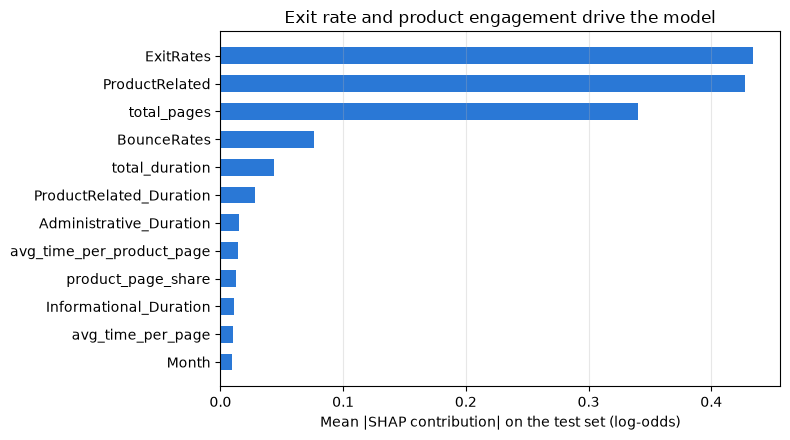

In [2]:
importance = pd.read_csv(PROJECT_ROOT / "reports" / "shap_global_importance.csv", index_col=0)
top = importance["purchase_intent"].dropna().head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=MAIN, height=0.6)
ax.set_xlabel("Mean |SHAP contribution| on the test set (log-odds)")
ax.set_title("Exit rate and product engagement drive the model")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Takeaway:** ExitRates, ProductRelated and total_pages do most of the work; everything else is small. This matches the feature selection in Week 2, which used different methods.

### Direction: high or low values?

Each dot is one test session. Colour shows whether the feature's value was high (red) or low (blue).

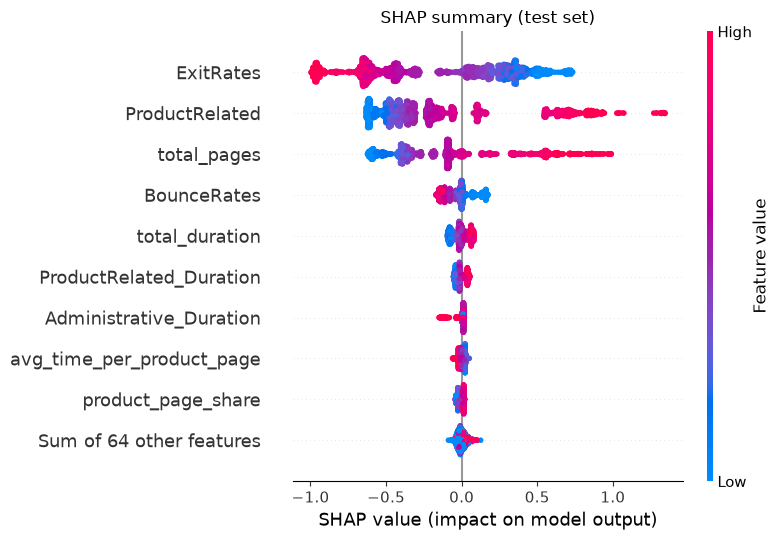

In [3]:
encoded = artifact.pipeline[:-1].transform(X_test)
names = [name.split("__", 1)[1] for name in artifact.pipeline.named_steps["preprocess"].get_feature_names_out()]
explanation = shap.Explanation(
    values=shap_explainer.explainer.shap_values(encoded),
    base_values=shap_explainer.base_value,
    data=encoded,
    feature_names=names,
)
shap.plots.beeswarm(explanation, max_display=10, show=False)
plt.title("SHAP summary (test set)")
plt.tight_layout()
plt.show()

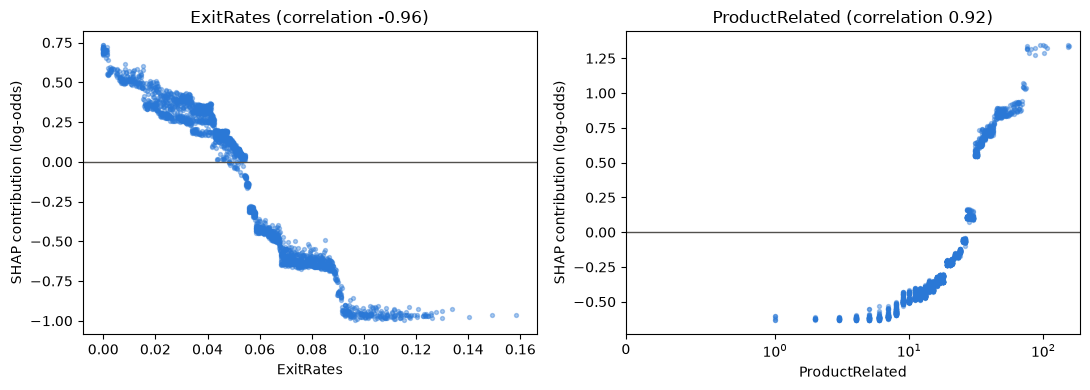

In [4]:
values = add_behavioural_features(X_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["ExitRates", "ProductRelated"]):
    ax.scatter(values[col], contributions[col], s=8, alpha=0.4, color=MAIN)
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_xlabel(col)
    ax.set_ylabel("SHAP contribution (log-odds)")
    corr = np.corrcoef(values[col], contributions[col])[0, 1]
    ax.set_title(f"{col} (correlation {corr:.2f})")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set_xlim(0, values["ProductRelated"].max() * 1.2)
plt.tight_layout()
plt.show()

**Takeaway:** the model has learned sensible rules. The higher the exit rate, the more it lowers the score (correlation −0.96), turning negative above an exit rate of about 0.05. The more product pages viewed, the more it raises the score (+0.92), with a sharp step at about 25–30 product pages where the contribution turns positive. Both are behaviours a CRO team can watch mid-session.

## 2. Revisiting PageValues

The PRD warns that PageValues would dominate. Here is the comparison model that includes it.

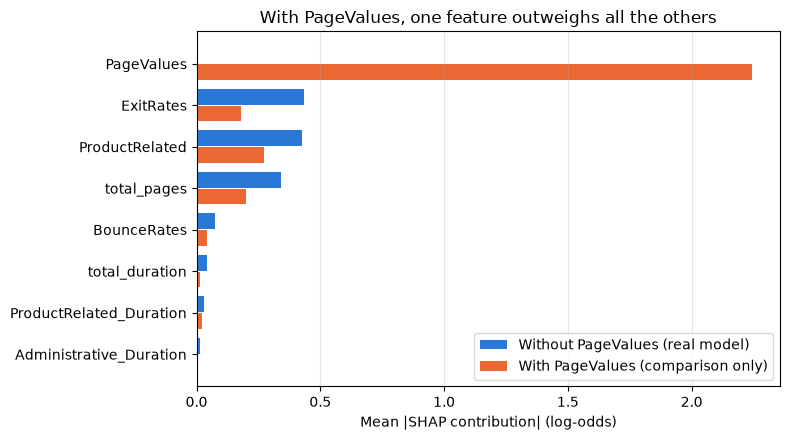

PageValues importance in the comparison model: 2.2447


In [5]:
both = importance.fillna(0)
both = both.loc[both.max(axis=1).sort_values(ascending=False).index[:8]].iloc[::-1]
y = np.arange(len(both))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(y + 0.2, both["purchase_intent"], height=0.38, color=MAIN, label="Without PageValues (real model)")
ax.barh(y - 0.2, both["purchase_intent_with_page_values"], height=0.38, color=REFERENCE, label="With PageValues (comparison only)")
ax.set_yticks(y, both.index)
ax.set_xlabel("Mean |SHAP contribution| (log-odds)")
ax.set_title("With PageValues, one feature outweighs all the others")
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("PageValues importance in the comparison model:", importance.loc["PageValues", "purchase_intent_with_page_values"])

**Takeaway:** in the comparison model, PageValues outweighs every other feature combined, and the behavioural features shrink. That is what leaning on a leaky feature looks like in an explanation. The real model, without it, spreads its attention over behaviours that are known mid-session, which is the point of leaving it out.

## 3. Local: why did this session get its score?

Two test sessions: the one the model is most confident will buy, and a typical low-scoring one.

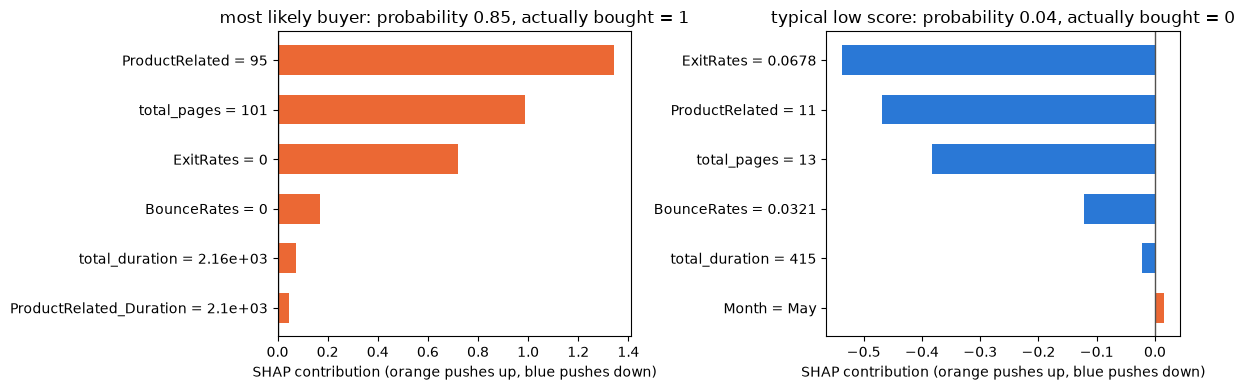

In [6]:
order = np.argsort(probabilities)
examples = {
    "most likely buyer": X_test.index[order[-1]],
    "typical low score": X_test.index[order[len(order) // 4]],
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, idx) in zip(axes, examples.items()):
    session = X_test.loc[[idx]]
    top = pd.DataFrame(shap_explainer.top_contributors(session, n=6)).iloc[::-1]
    colours = [REFERENCE if c > 0 else MAIN for c in top["contribution"]]
    ax.barh([f"{f} = {v:.3g}" if isinstance(v, float) else f"{f} = {v}" for f, v in zip(top["feature"], top["value"])],
            top["contribution"], color=colours, height=0.6)
    ax.axvline(0, color=INK, linewidth=1)
    p = probabilities[X_test.index.get_loc(idx)]
    ax.set_title(f"{label}: probability {p:.2f}, actually bought = {y_test.loc[idx]}")
    ax.set_xlabel("SHAP contribution (orange pushes up, blue pushes down)")
plt.tight_layout()
plt.show()

**Takeaway:** the most likely buyer viewed 95 product pages with an exit rate of 0, which push its score up strongly (probability 0.85; it did buy). The typical low-scoring session has a higher exit rate (0.068) and only 11 product pages, which pull it down (probability 0.04; it did not buy). This is the answer the CRO team gets for every session in the API and dashboard.

## 4. LIME: a second opinion on the same sessions

In [7]:
for label, idx in examples.items():
    result = lime_explainer.explain(X_test.loc[[idx]])
    print(f"{label} (local fit R² = {result['local_fit_r2']})")
    display(pd.DataFrame(result["conditions"]))

most likely buyer (local fit R² = 0.783)


,condition,weight,effect
0,ProductRelated > 25.00,0.2653,increases
1,ExitRates <= 0.04,0.0786,increases
2,BounceRates <= 0.01,0.0207,increases
3,Administrative > 3.00,0.0136,increases
4,ProductRelated_Duration > 903.69,0.0132,increases


typical low score (local fit R² = 0.1829)


,condition,weight,effect
0,ProductRelated <= 11.00,-0.1122,decreases
1,0.05 < ExitRates <= 0.07,-0.0415,decreases
2,268.98 < ProductRelated_Duration <= 498.93,-0.0169,decreases
3,28.61 < Administrative_Duration <= 56.33,0.0123,increases
4,BounceRates > 0.03,-0.0101,decreases


### How often do SHAP and LIME agree?

For 40 random test sessions: is SHAP's most important feature among LIME's top five, pointing the same way?

In [8]:
sample = X_test.sample(40, random_state=settings.random_seed)
found = same_direction = 0
fits = []
for idx in sample.index:
    session = sample.loc[[idx]]
    top = shap_explainer.top_contributors(session, n=1)[0]
    lime = lime_explainer.explain(session, n=5)
    fits.append(lime["local_fit_r2"])
    matches = [c for c in lime["conditions"] if top["feature"] in c["condition"]]
    if matches:
        found += 1
        same_direction += matches[0]["effect"] == top["effect"]

print(f"SHAP's top feature in LIME's top 5: {found}/40")
print(f"Same direction when found: {same_direction}/{found}")
print(f"LIME local fit R²: median {np.median(fits):.2f}, range {min(fits):.2f} to {max(fits):.2f}")

SHAP's top feature in LIME's top 5: 40/40
Same direction when found: 40/40
LIME local fit R²: median 0.16, range 0.03 to 0.79


**Takeaway:** the two methods agree on what matters and which way it pushes: SHAP's top feature was in LIME's top five, with the same direction, for all 40 sessions. But LIME's simple model usually fits poorly (median R² around 0.16), so its exact weights are rough. We use SHAP for the numbers in the API and dashboard, and LIME as an independent check.

## 5. Limits of these explanations

- **Explaining the model, not the world:** SHAP says why the *model* scored a session this way. It does not prove that lowering a visitor's exit rate would make them buy.
- **Correlated features share credit:** ProductRelated and total_pages move together, so their contributions overlap.
- **Units:** SHAP is in log-odds and LIME in probability, so their numbers cannot be compared directly, only their order and direction.